In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score, PredictionErrorDisplay

In [24]:
df = pd.read_csv("multiple_linear_regression_dataset.csv")
TARGET = "income"
df = df.dropna(subset=[TARGET])
X = df.drop(columns=[TARGET])
y = df[TARGET]

In [25]:
# 2. Preprocessing + model
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="mean")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

pipe = Pipeline([("preprocess", preprocess), ("model", LinearRegression())])


In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(
    pipe, X_train, y_train, cv=cv,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    return_train_score=True,
)
print(f"CV RMSE: {-res['test_rmse'].mean():.3f} ± {res['test_rmse'].std():.3f}")
print(f"CV R²:   {res['test_r2'].mean():.3f} ± {res['test_r2'].std():.3f}")
print(f"Train RMSE (CV): {-res['train_rmse'].mean():.3f}")  # big gap vs CV RMSE = overfitting


CV RMSE: 1600.271 ± 352.057
CV R²:   0.863 ± 0.097
Train RMSE (CV): 1280.165


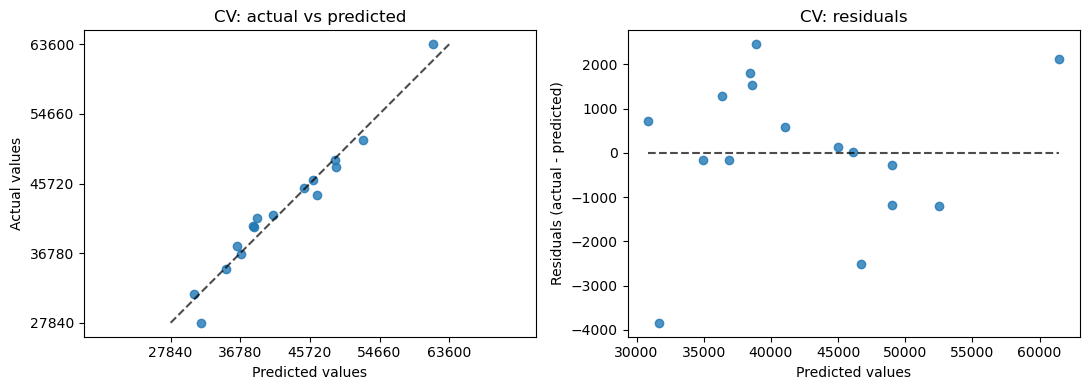

In [27]:
y_cv_pred = cross_val_predict(pipe, X_train, y_train, cv=cv)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
PredictionErrorDisplay.from_predictions(y_train, y_cv_pred, kind="actual_vs_predicted", ax=ax[0])
PredictionErrorDisplay.from_predictions(y_train, y_cv_pred, kind="residual_vs_predicted", ax=ax[1])
ax[0].set_title("CV: actual vs predicted")
ax[1].set_title("CV: residuals")
plt.tight_layout()
plt.show()

In [28]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
print(f"Test R²:   {r2_score(y_test, y_pred):.3f}")

Test RMSE: 868.215
Test R²:   0.939
